# Front tracking playground

Choose a flux, initial data and observation window, then explore the moving fronts.


**Run all cells from top to bottom.** In Jupyter choose **Run → Run All Cells**;
in Colab choose **Runtime → Run all**. No account credentials, repository clone,
or file upload beyond this notebook is needed. Initial setup installs missing
NumPy, Matplotlib and ipywidgets. A CPU runtime is sufficient.

Each notebook carries a readable snapshot of the solver for standalone use.
Inside a local project checkout it uses `src/fronttrack` instead. Restart the
kernel/runtime after changing solver versions. GitHub displays saved figures;
open the notebook in Jupyter or Colab to use its controls.


In [1]:
# Install only missing dependencies into this notebook's Python environment.
import sys, subprocess, importlib.util
if sys.version_info < (3, 10):
    raise RuntimeError("Use Python 3.10 or newer")
requirements = {"numpy": "numpy>=1.24", "matplotlib": "matplotlib>=3.7",
                "ipywidgets": "ipywidgets>=8,<9"}
missing = [spec for name, spec in requirements.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
if "google.colab" in sys.modules:
    from google.colab import output
    output.enable_custom_widget_manager()
%matplotlib inline


In [2]:
# Standalone source snapshot. Generated by tools/build_notebooks.py; do not edit here.
from pathlib import Path
import tempfile, hashlib, json
BUNDLED_SOURCES = {'__init__.py': '"""Dafermos polygonal-flux front tracking for scalar conservation laws on R and S^1.\n\nPublic API (read the modules in this order):\n\n- ``DiscreteFlux``   (flux.py)          polygonal flux on a state grid\n- ``solve_riemann``  (riemann.py)       entropy envelope of one jump\n- ``Front``, ``FrontCollection``, ``initial_fronts`` (fronts.py)\n- ``next_interaction``, ``resolve_interaction``      (interactions.py)\n- ``AnchoredEventDriver`` (events.py)   shared event queue behind both drivers\n- ``FrontTracker``   (solver.py)        event-driven evolution driver on R\n- ``Circle``, ``PeriodicFrontTracker`` (periodic.py)  the same driver on S^1\n\nInstall once with ``python -m pip install -e .`` from the repository root, or\nlet the repository\'s scripts add ``src/`` to the path themselves.\n"""\nfrom .flux import DiscreteFlux\nfrom .riemann import solve_riemann\nfrom .fronts import Front, FrontCollection, initial_fronts\nfrom .interactions import next_interaction, resolve_interaction\nfrom .solver import FrontTracker\nfrom .periodic import Circle, PeriodicFrontTracker\n\n__version__ = "0.3.0"\n__all__ = [\n    "DiscreteFlux", "solve_riemann", "Front", "FrontCollection", "initial_fronts",\n    "next_interaction", "resolve_interaction", "FrontTracker",\n    "Circle", "PeriodicFrontTracker",\n]\n', 'events.py': '"""Event queue shared by the real-line and circle drivers (internal).\n\nA front moves on a straight line between collisions, so it never needs to be\nstepped. During ``run`` each front keeps an anchor: its position ``x`` at the\nanchor time ``t0``; the position at time t is ``x + speed * (t - t0)``. Only\nthe fronts created at an event get new anchors, so surviving fronts need no\nposition update during a collision.\n\nPredicted collisions sit in a binary heap. Front i owns the prediction for\nthe gap to its right neighbour. Whenever that neighbour changes, front i\'s\n``version`` is bumped and a new prediction pushed; the old heap entry still\nexists but no longer matches the version, so it is discarded when it reaches\nthe top (lazy invalidation). A retired front is bumped the same way.\n\nWhen ``run`` returns, or raises, every front is moved to its anchor at the\ncurrent time again, so ``Front.x`` is correct whenever a user reads it.\n"""\n\nfrom bisect import bisect_left\nfrom itertools import count\nimport heapq\nimport math\n\n\nclass AnchoredEventDriver:\n    """Shared ``run`` loop. Subclasses supply the geometry of one domain.\n\n    Required attributes: ``fronts`` (ordered list), ``time``, ``event_count``,\n    ``max_events``, ``record_history``, ``segments``. Required methods:\n    ``_pair(i)`` -> (left, right, gap) or None, ``_resolve_cluster(i)``,\n    ``_record_path(x0, t0, speed, t1)`` and ``_normalize()``.\n    """\n\n    _event_limit_message = "Event limit reached; inspect data or raise max_events"\n\n    # ------------------------------------------------------------ anchors\n    def _position(self, front):\n        """Position of an anchored front at the current clock, in closed form."""\n        return front.x + front.speed * (self.time - front.t0)\n\n    def _retire(self, front):\n        """Invalidate a front\'s queued prediction and record its final path."""\n        front.version += 1\n        if self.record_history and self.time > front.t0:\n            self._record_path(front.x, front.t0, front.speed, self.time)\n\n    def _settle(self):\n        """Move every anchor to the current time; afterwards ``x`` is exact."""\n        t, record = self.time, self.record_history\n        for front in self.fronts:\n            if front.t0 != t:\n                if record and t > front.t0:\n                    self._record_path(front.x, front.t0, front.speed, t)\n                front.x += front.speed * (t - front.t0)\n                front.t0 = t\n        self._normalize()\n\n    def _normalize(self):\n        """Hook for a common coordinate shift after settling (circle only)."""\n\n    # -------------------------------------------------------------- queue\n    def _start_queue(self):\n        """Anchor all fronts now and predict every adjacent pair, O(F log F).\n\n        Rebuilt at the start of every ``run`` so edits made to ``fronts``\n        between runs are respected, exactly as the old full rescan did.\n        """\n        t = self.time\n        for front in self.fronts:\n            front.t0 = t\n        self._heap, self._seq = [], count()\n        self._refresh(range(len(self.fronts)))\n\n    def _refresh(self, indices):\n        """Replace the predictions owned by the fronts at these indices."""\n        heap, seq, t = self._heap, self._seq, self.time\n        for i in indices:\n            if not 0 <= i < len(self.fronts):\n                continue\n            self.fronts[i].version += 1\n            pair = self._pair(i)\n            if pair is None:\n                continue\n            left, right, gap = pair\n            closing = left.speed - right.speed\n            if closing > 0:\n                # Equal or separating speeds never collide, even at the same\n                # point. Clamp tiny negative gaps (roundoff) to "now".\n                wait = max(0.0, gap / closing)\n                # Ties in time go to the leftmost meeting point, then FIFO.\n                heapq.heappush(heap, (t + wait, self._position(left) + left.speed * wait,\n                                      next(seq), left, left.version))\n\n    def _next_event(self):\n        """Earliest valid prediction as (time, owner front), or (inf, None)."""\n        heap = self._heap\n        if len(heap) > 4 * len(self.fronts) + 64:\n            # Too many stale entries: rebuild from the live pairs.\n            heap.clear()\n            self._refresh(range(len(self.fronts)))\n        while heap:\n            t, _, _, front, version = heap[0]\n            if front.version == version:\n                return t, front\n            heapq.heappop(heap)\n        return math.inf, None\n\n    def _locate(self, front):\n        """Index of a live front: binary search on positions, then a local walk.\n\n        Positions at the current time are sorted up to roundoff. Fronts that\n        roundoff can misorder nearly coincide, so the walk outward from the\n        bisection point meets the target after a few steps.\n        """\n        fronts, t = self.fronts, self.time\n        i = bisect_left(fronts, self._position(front),\n                        key=lambda f: f.x + f.speed * (t - f.t0))\n        lo, hi, n = i - 1, i, len(fronts)\n        while lo >= 0 or hi < n:\n            if hi < n:\n                if fronts[hi] is front:\n                    return hi\n                hi += 1\n            if lo >= 0:\n                if fronts[lo] is front:\n                    return lo\n                lo -= 1\n        raise RuntimeError("Queued front is missing from the front list")\n\n    # ---------------------------------------------------------------- run\n    def run(self, final_time):\n        """Advance to absolute final_time, resolving events exactly at that time.\n\n        Returns self for chaining. Calling again continues the current solution;\n        going backward is rejected. An event-limit error leaves the state at\n        its last completed event so it can be inspected or resumed.\n        """\n        if not math.isfinite(final_time) or final_time < self.time:\n            raise ValueError("final_time must be finite and at least the current time")\n        self._start_queue()\n        try:\n            while True:\n                t, front = self._next_event()\n                if front is None or t > final_time:\n                    # No interaction before the observation time: translation.\n                    self.time = float(final_time)\n                    return self\n                if self.event_count >= self.max_events:\n                    raise RuntimeError(self._event_limit_message)\n                heapq.heappop(self._heap)\n                self.time = max(self.time, t)\n                self._resolve_cluster(self._locate(front))\n                # A separate collision at the same time is the next heap entry.\n        finally:\n            self._settle()\n            self._heap = []  # Nothing queued survives outside run().\n', 'flux.py': '"""Approximate f(u) by the polygonal line through a fixed set of state nodes.\n\nPhysical states (for example u=0.5) and node indices (for example i=20) are\nseparate concepts: ``value``/``state_index`` take states, while ``rh``/``slope``\ntake indices. Fronts store indices so interaction states stay on this grid.\n"""\n\nimport operator\n\nimport numpy as np\n\n\nclass DiscreteFlux:\n    """Continuous piecewise linear flux on a strictly increasing state grid.\n\n    ``f`` must accept a NumPy array and return finite values of the same shape,\n    or a scalar for a constant flux. Nonuniform grids are supported. Arrays are\n    copied and made read-only so precomputed interval slopes remain consistent.\n    """\n\n    def __init__(self, f, u_grid):\n        # Validate once at construction; every Riemann solve reuses these nodes.\n        grid = np.array(u_grid, dtype=float, copy=True)\n        if grid.ndim != 1 or len(grid) < 2 or not np.all(np.isfinite(grid)):\n            raise ValueError("u_grid must contain at least two finite values")\n        if np.any(np.diff(grid) <= 0):\n            raise ValueError("u_grid must be strictly increasing")\n\n        values = np.asarray(f(grid), dtype=float)\n        if values.ndim == 0:\n            values = np.full_like(grid, values)\n        if values.shape != grid.shape or not np.all(np.isfinite(values)):\n            raise ValueError("f must return finite values matching u_grid")\n\n        self.f = f  # Keep the original callable for comparisons with f_h.\n        self.u_grid = grid\n        self.f_values = values.copy()\n        self._slopes = np.diff(self.f_values) / np.diff(grid)\n        for array in (self.u_grid, self.f_values, self._slopes):\n            array.flags.writeable = False\n\n    def validate_index(self, i) -> int:\n        """Accept Python/NumPy integers; reject fractional or out-of-range indices."""\n        i = operator.index(i)\n        if not 0 <= i < len(self.u_grid):\n            raise IndexError("State index out of bounds")\n        return i\n\n    def slope(self, i) -> float:\n        """Return the precomputed slope on [u_grid[i], u_grid[i+1]]."""\n        i = self.validate_index(i)\n        if i == len(self.u_grid) - 1:\n            raise IndexError("Slope index out of bounds")\n        return float(self._slopes[i])\n\n    def rh(self, iL, iR) -> float:\n        """Rankine–Hugoniot speed: flux difference divided by state difference."""\n        iL, iR = self.validate_index(iL), self.validate_index(iR)\n        if iL == iR:\n            raise ValueError("RH speed undefined for equal states")\n        return float(\n            (self.f_values[iR] - self.f_values[iL])\n            / (self.u_grid[iR] - self.u_grid[iL])\n        )\n\n    def _states(self, u):\n        """Normalize scalar/array input and reject extrapolation outside the grid."""\n        u = np.asarray(u, dtype=float)\n        if (not np.all(np.isfinite(u)) or np.any(u < self.u_grid[0])\n                or np.any(u > self.u_grid[-1])):\n            raise ValueError("State outside discretised flux range")\n        return u\n\n    def _interval_indices(self, u):\n        """Locate already validated states without repeating range checks."""\n        # side=\'right\' chooses the interval beginning at an interior node.\n        # At the final node there is no right interval, so use the last one.\n        return np.clip(\n            np.searchsorted(self.u_grid, u, side="right") - 1,\n            0, len(self.u_grid) - 2,\n        )\n\n    def interval_index(self, u):\n        """Right interval at an interior knot; last interval at the endpoint."""\n        u = self._states(u)\n        indices = self._interval_indices(u)\n        return int(indices) if u.ndim == 0 else indices\n\n    def value(self, u):\n        """Evaluate f_h, preserving array shape or returning a float for a scalar."""\n        u = self._states(u)\n        indices = self._interval_indices(u)\n        # Interpolation reuses slopes instead of dividing again for every query.\n        value = self.f_values[indices] + (u - self.u_grid[indices]) * self._slopes[indices]\n        return float(value) if u.ndim == 0 else value\n\n    def state_index(self, u):\n        """Quantize to the nearest node (ties choose the lower node). No clipping."""\n        u = self._states(u)\n        # Bracket each state, then compare distances to the two candidate nodes.\n        hi = np.clip(np.searchsorted(self.u_grid, u), 1, len(self.u_grid) - 1)\n        lo = hi - 1\n        indices = np.where(u - self.u_grid[lo] <= self.u_grid[hi] - u, lo, hi)\n        return int(indices) if u.ndim == 0 else indices\n', 'fronts.py': '"""Represent moving jumps and expand piecewise constant initial data into fronts.\n\nA single initial jump can generate several fronts (a rarefaction staircase),\none front (for example a shock), or none when its two states are equal.\n"""\n\nfrom dataclasses import dataclass, field\nfrom itertools import pairwise\nimport math\n\nimport numpy as np\n\nfrom .riemann import solve_riemann\n\n\n@dataclass(slots=True)\nclass Front:\n    """One moving discontinuity with a constant speed until its next collision.\n\n    ``x`` is its current position. ``iL``/``iR`` are flux-node indices on its\n    left/right. Slots reduce per-front memory.\n\n    While a driver\'s ``run`` is in progress, ``x`` is instead the position at\n    the anchor time ``t0`` (see events.py); ``run`` restores the current\n    position before it returns. ``version`` stamps the front\'s queued\n    collision prediction. Neither takes part in comparison or repr.\n    """\n\n    x: float\n    iL: int\n    iR: int\n    speed: float\n    t0: float = field(default=0.0, compare=False, repr=False)\n    version: int = field(default=0, compare=False, repr=False)\n\n\nclass FrontCollection:\n    """Spatially ordered fronts; ownership and collision handling live in the driver."""\n\n    def __init__(self, fronts):\n        self.fronts = list(fronts)\n\n    def advance(self, dt: float) -> None:\n        """Translate all fronts by speed * dt; caller must prevent crossings."""\n        if not math.isfinite(dt) or dt < 0:\n            raise ValueError("dt must be finite and nonnegative")\n        for front in self.fronts:\n            front.x += front.speed * dt\n\n\ndef initial_fronts(positions, states, flux) -> FrontCollection:\n    """Expand N strictly ordered jumps and N+1 integer state indices.\n\n    The first and last states extend to infinity. Multiple outgoing fronts from\n    one jump start at the same point, already ordered by their Riemann speeds.\n    """\n    positions = np.asarray(positions, dtype=float)\n    states = [flux.validate_index(i) for i in states]\n    if positions.ndim != 1 or len(states) != len(positions) + 1:\n        raise ValueError("Need N jump positions and N+1 state indices")\n    if not np.all(np.isfinite(positions)) or np.any(np.diff(positions) <= 0):\n        raise ValueError("Jump positions must be finite and strictly increasing")\n\n    # Keep the initial spatial order. Sorting by state or by speed globally\n    # would destroy the ordering of the piecewise constant solution.\n    fronts = []\n    for x, (iL, iR) in zip(positions, pairwise(states)):\n        for left, right, speed in solve_riemann(iL, iR, flux):\n            fronts.append(Front(float(x), left, right, speed))\n    return FrontCollection(fronts)\n', 'interactions.py': '"""Predict adjacent collisions and solve the Riemann problem they create.\n\nOnly neighbors need checking: a front cannot reach a non-neighbor without\nfirst meeting the front between them. ``next_interaction`` is the readable\nO(N) scan over all neighbours. The drivers do not call it on every event:\nthey keep the same pair predictions in a priority queue (events.py).\n"""\n\nfrom itertools import pairwise\nimport math\n\nfrom .fronts import Front, FrontCollection\nfrom .riemann import solve_riemann\n\n\ndef next_interaction(fronts) -> tuple[float, int | None]:\n    """Return (relative waiting time, left pair index), or (inf, None).\n\n    Accept either a front list or FrontCollection. Ties select the first pair;\n    the driver subsequently handles any other event at the same absolute time.\n    """\n    fronts = fronts.fronts if isinstance(fronts, FrontCollection) else fronts\n    best_time, index = math.inf, None\n    # pairwise iterates without allocating the full fronts[1:] list each event.\n    for i, (left, right) in enumerate(pairwise(fronts)):\n        closing_speed = left.speed - right.speed\n        if closing_speed > 0:\n            # Equal or separating speeds never collide, even at the same point.\n            # Clamp tiny negative gaps due to roundoff to an immediate event.\n            dt = max(0.0, (right.x - left.x) / closing_speed)\n            if dt < best_time:\n                best_time, index = dt, i\n    return best_time, index\n\n\ndef resolve_interaction(front_i, front_j, flux) -> list[Front]:\n    """Replace a collided cluster using only its two exterior states.\n\n    Caller advances incoming fronts to the collision point first. Arguments\n    may be the first and last fronts of a multiway cluster. Intermediate states\n    occupy zero width at the event and disappear from the new local problem.\n    """\n    x = 0.5 * (front_i.x + front_j.x)\n    return [Front(x, left, right, speed)\n            for left, right, speed in solve_riemann(front_i.iL, front_j.iR, flux)]\n', 'periodic.py': '"""Event-driven scalar front tracking on the circle S^1 = R/(L Z).\n\nSame equation as solver.py, u_t + f(u)_x = 0, but on a compact domain with no\nboundary: a front leaving one end of the chart [origin, origin + L) re-enters\nat the other and can collide with fronts there. This is intrinsic 1D evolution,\nnot a 2D PDE restricted to a curve, and there are no far-field states.\n\nFronts live on an ordered lift spanning at most one circumference. A common\ntranslation by an integer number of periods keeps coordinates small; individual\nfronts are never independently wrapped and sorted during evolution. The event\nloop (anchored fronts, priority queue) is shared with solver.py via events.py.\n"""\nfrom dataclasses import dataclass, replace\nimport math\n\nimport numpy as np\n\nfrom .events import AnchoredEventDriver\nfrom .fronts import Front, FrontCollection\nfrom .interactions import resolve_interaction\nfrom .riemann import solve_riemann\n\n\n@dataclass(frozen=True)\nclass Circle:\n    """Flat circle R/(length Z), represented on [origin, origin + length)."""\n    length: float = 1.0\n    origin: float = 0.0\n\n    def __post_init__(self):\n        if not math.isfinite(self.length) or self.length <= 0:\n            raise ValueError("length must be positive and finite")\n        if (not math.isfinite(self.origin) or not math.isfinite(self.origin + self.length)\n                or self.origin + self.length <= self.origin):\n            raise ValueError("origin and endpoint must be finite and distinguishable")\n\n    @property\n    def dimension(self):\n        return 1\n\n    @property\n    def volume(self):\n        return self.length\n\n    def wrap(self, points):\n        """Map finite coordinates into [origin, origin+length), same shape."""\n        points = np.asarray(points, dtype=float)\n        if not np.all(np.isfinite(points)):\n            raise ValueError("coordinates must be finite")\n        result = self.origin + np.remainder(points - self.origin, self.length)\n        # remainder can return exactly `length` for tiny negative inputs\n        # (e.g. -1e-17 % 1 == 1.0 in floating point); fold that onto the origin.\n        result = np.where(result >= self.origin + self.length, self.origin, result)\n        return float(result) if points.ndim == 0 else result\n\n\nclass PeriodicFrontTracker(AnchoredEventDriver):\n    """Evolve u_t + f(u)_x = 0 on Circle.\n\n    N breakpoints require N states: state[j] occupies the positively oriented\n    arc from positions[j] to positions[j+1], including the final wraparound arc.\n    For a constant solution, use no breakpoints and one state. All states are\n    flux-node indices; from_values quantizes physical values. run(T) uses\n    absolute time. Live fronts are internal; snapshot() returns copies.\n    """\n    _event_limit_message = "Event limit reached; inspect or increase max_events"\n\n    def __init__(self, flux, positions, states, *, domain=None,\n                 position_tol=1e-12, max_events=100000, record_history=False):\n        self.domain = Circle() if domain is None else domain\n        if not isinstance(self.domain, Circle):\n            raise TypeError("PeriodicFrontTracker currently supports Circle only")\n        self.flux = flux\n        p = np.asarray(positions, dtype=float)\n        states = [flux.validate_index(s) for s in states]\n        if p.ndim != 1 or not np.all(np.isfinite(p)) or np.any(np.diff(p) <= 0):\n            raise ValueError("positions must be finite and strictly increasing")\n        if np.any(p < self.domain.origin) or np.any(p >= self.domain.origin + self.domain.length):\n            raise ValueError("positions must lie in the half-open domain interval")\n        if len(states) != (len(p) if len(p) else 1):\n            raise ValueError("Need N positions and N states, or no positions and one constant state")\n        if not math.isfinite(position_tol) or not 0 <= position_tol < self.domain.length / 4:\n            raise ValueError("position_tol must be finite and in [0, length/4)")\n        if isinstance(max_events, bool) or not isinstance(max_events, int) or max_events < 1:\n            raise ValueError("max_events must be a positive integer")\n        self.position_tol, self.max_events = position_tol, max_events\n        self.time, self.event_count = 0.0, 0\n        self.record_history = record_history\n        self.segments = []\n        # With no fronts the circle carries one constant; remember which. It is\n        # refreshed at every collision so full annihilation leaves the right value.\n        self._constant_state = states[0]\n        # Breakpoint j separates states[j-1] (its left arc) from states[j]. For\n        # j=0, Python\'s states[-1] is the final arc wrapping through the seam,\n        # so every breakpoint, including the first, gets a genuine left state.\n        # Fans from one breakpoint share its position, ordered by speed.\n        self.collection = FrontCollection([\n            Front(float(x), a, b, speed)\n            for j, x in enumerate(p)\n            for a, b, speed in solve_riemann(states[j - 1], states[j], flux)\n        ])\n\n    @classmethod\n    def from_values(cls, flux, positions, values, **kwargs):\n        """Quantize physical values to nearest flux nodes (no clipping)."""\n        return cls(flux, positions, flux.state_index(values), **kwargs)\n\n    @classmethod\n    def from_function(cls, flux, function, *, cells=100, domain=None, **kwargs):\n        """Midpoint sample and quantize a function; these are not cell averages."""\n        domain = Circle() if domain is None else domain\n        if not isinstance(domain, Circle):\n            raise TypeError("PeriodicFrontTracker currently supports Circle only")\n        if isinstance(cells, bool) or not isinstance(cells, int) or cells < 1:\n            raise ValueError("cells must be a positive integer")\n        # Left cell edges only: the last cell ends at the seam, which is the\n        # first edge again, so the endpoint must not be repeated.\n        edges = domain.origin + np.arange(cells) * domain.length / cells\n        values = np.asarray(function(edges + domain.length / (2 * cells)), dtype=float)\n        if values.ndim == 0:\n            values = np.full(cells, values)\n        return cls.from_values(flux, edges, values, domain=domain, **kwargs)\n\n    @property\n    def fronts(self):\n        """Live fronts in cyclic order on the current lift. Do not modify."""\n        return self.collection.fronts\n\n    def _pair(self, i):\n        """(left, right, gap now) for the pair owned by front i, or None.\n\n        Same closing-speed test as the real-line driver, but adjacency is\n        cyclic: the last front\'s right neighbour is the first front, one\n        circumference further along. Only that wraparound pair needs +L: the\n        lift is ordered and spans at most one circumference.\n        """\n        fronts = self.fronts\n        n = len(fronts)\n        if n < 2 or not 0 <= i < n:\n            return None\n        left = fronts[i]\n        right = fronts[i + 1] if i + 1 < n else fronts[0]\n        gap = self._position(right) - self._position(left)\n        return left, right, gap + (self.domain.length if i + 1 == n else 0.0)\n\n    def _record_path(self, x0, t0, speed, t1):\n        """Record a straight path, split at chart seams (no false diagonals)."""\n        o, length, dt = self.domain.origin, self.domain.length, t1 - t0\n        end = x0 + speed * dt\n        cuts = [0.0, dt]\n        if speed != 0:\n            lo, hi = sorted((x0, end))\n            for k in range(math.floor((lo - o) / length) + 1, math.ceil((hi - o) / length)):\n                crossing = (o + k * length - x0) / speed\n                if 0 < crossing < dt:\n                    cuts.append(crossing)\n        cuts.sort()\n        for a, b in zip(cuts[:-1], cuts[1:]):\n            shift = math.floor((x0 + speed * (a + b) / 2 - o) / length) * length\n            self.segments.append((x0 + speed * a - shift, t0 + a,\n                                  x0 + speed * b - shift, t0 + b))\n\n    def _normalize(self):\n        """Shift the whole lift by whole periods so front 0 is in the chart.\n\n        The shift is the same for every front (an integer number of periods up\n        to roundoff), so cyclic order and all separations are preserved; it\n        only stops coordinates growing without bound over many circuits.\n        """\n        if self.fronts:\n            first = self.fronts[0].x\n            shift = first - self.domain.wrap(first)\n            if shift:\n                for front in self.fronts:\n                    front.x -= shift\n\n    def _resolve_cluster(self, pair):\n        """Replace the collision cluster containing ``pair`` and its neighbour.\n\n        Runs at the collision time. As on the line, the new Riemann problem\n        uses only the cluster\'s two exterior states.\n        Scan cyclic indices on one lift, then remove a seam-spanning cluster\n        in two slices so each surviving front moves at most once.\n        """\n        fronts, length, position = self.fronts, self.domain.length, self._position\n        n = len(fronts)\n\n        def lifted_position(index):\n            turns, i = divmod(index, n)\n            return position(fronts[i]) + turns * length\n\n        first, last = pair, pair + 1\n        x = (lifted_position(first) + lifted_position(last)) / 2\n        # The grouping tolerance is local to the circle, independent of how\n        # many periods the fronts have travelled together.\n        tol = self.position_tol + 16 * np.finfo(float).eps * length\n        while last - first + 1 < n and abs(lifted_position(first - 1) - x) <= tol:\n            first -= 1\n        while last - first + 1 < n and abs(lifted_position(last + 1) - x) <= tol:\n            last += 1\n\n        if first < 0:\n            # Insert outgoing fronts at the tail, on the surviving list\'s lift.\n            first += n\n            last += n\n            x += length\n        self._constant_state = fronts[first].iL\n        outgoing = resolve_interaction(fronts[first], fronts[last % n], self.flux)\n        for front in outgoing:\n            front.x, front.t0 = x, self.time\n        if last >= n:\n            prefix = last - n + 1\n            for front in fronts[:prefix]:\n                self._retire(front)\n            del fronts[:prefix]\n            first -= prefix\n            last = len(fronts) - 1\n        for front in fronts[first:last + 1]:\n            self._retire(front)\n        fronts[first:last + 1] = outgoing\n        self.event_count += 1\n        n = len(fronts)\n        if n:\n            # New fronts and the cyclic left neighbour own changed pairs.\n            self._refresh({k % n for k in range(first - 1, first + len(outgoing))})\n\n    def sample(self, x):\n        """Right-continuous values at any finite coordinates (wrapped), same shape."""\n        x = np.asarray(self.domain.wrap(x))\n        if not self.fronts:\n            result = np.full(x.shape, self.flux.u_grid[self._constant_state])\n        else:\n            first = self.fronts[0].x\n            # Represent each query on the fronts\' lift [first, first+L). Then\n            # front 0 is at or left of every query; the state right of the last\n            # front at or left of the query is the answer. side=\'right\' crosses\n            # coincident fans, selecting their outermost right state.\n            lifted = first + np.remainder(x - first, self.domain.length)\n            positions = [front.x for front in self.fronts]\n            indices = np.searchsorted(positions, lifted, side="right") - 1\n            result = self.flux.u_grid[np.array([f.iR for f in self.fronts])[indices]]\n        return float(result) if x.ndim == 0 else result\n\n    def snapshot(self):\n        """Copied fronts on the current ordered lift (not necessarily in [0,L))."""\n        return [replace(front) for front in self.fronts]\n\n    def integral(self):\n        """Exact step-function mass over the whole circle, up to roundoff."""\n        if not self.fronts:\n            return float(self.domain.length * self.flux.u_grid[self._constant_state])\n        fronts = self.fronts\n        # Arc from each front to the next carries that front\'s right state;\n        # the last arc wraps to the first front one circumference later.\n        return math.fsum(\n            ((fronts[i + 1].x if i + 1 < len(fronts) else fronts[0].x + self.domain.length) - f.x)\n            * self.flux.u_grid[f.iR] for i, f in enumerate(fronts)\n        )\n\n    def total_variation(self):\n        """Sum of |jumps| around the whole circle (nonincreasing in exact arithmetic)."""\n        return math.fsum(abs(self.flux.u_grid[f.iR] - self.flux.u_grid[f.iL]) for f in self.fronts)\n', 'riemann.py': '"""Resolve one initial jump using an entropy envelope of the polygonal flux.\n\nAn increasing jump uses the lower convex envelope; a decreasing jump uses the\nupper concave envelope. Envelope edges become moving fronts. In both cases,\nthe returned fronts are ordered from left to right in physical space.\n"""\n\nimport math\nfrom itertools import pairwise\n\nimport numpy as np\n\nfrom .flux import DiscreteFlux\n\n# Each wave stores node indices, followed by its physical propagation speed.\nWave = tuple[int, int, float]\n\n# Collinearity allowance, relative to the magnitudes entering the test. Nodes\n# within this vertical distance of a chord are treated as lying on it. Measured\n# worst case for mathematically collinear u**3 nodes is about 1.3 eps; genuine\n# gaps on grids up to 2001 nodes are above 1e9 eps.\n_COLLINEAR_FACTOR = 16 * np.finfo(float).eps\n\n\ndef _local_gaps(flux: DiscreteFlux):\n    """Vertical offset of each interior node from its neighbours\' chord, and\n    the roundoff allowance for that offset (same formula as the hull stack)."""\n    u, f = flux.u_grid, flux.f_values\n    a, b, c = slice(None, -2), slice(1, -1), slice(2, None)\n    rise, run = f[c] - f[a], u[c] - u[a]\n    gap = (f[b] - f[a]) - rise * ((u[b] - u[a]) / run)\n    u_scale = max(abs(u[0]), abs(u[-1]))\n    scale = (np.maximum(np.maximum(np.abs(f[a]), np.abs(f[b])), np.abs(f[c]))\n             + np.abs(rise / run) * u_scale)\n    return gap, _COLLINEAR_FACTOR * scale\n\n\ndef _hull_candidates(flux: DiscreteFlux):\n    """Interior nodes that can be vertices of a lower/upper envelope.\n\n    A vertex of the lower convex envelope of any node range lies strictly\n    below the chord joining ANY two range nodes on either side of it, in\n    particular its two grid neighbours. So a node clearly above the chord of\n    its neighbours (locally concave by more than the roundoff allowance) is\n    never a lower-envelope vertex, and symmetrically for the upper envelope.\n    Nodes within the allowance of collinear stay candidates; the stack in\n    solve_riemann applies its own allowance to them exactly as before.\n\n    Returns two sorted index arrays (lower, upper), computed once per flux\n    in O(n) and cached on it. For a convex flux the upper array is empty, so\n    a shock between any two states costs O(log n) instead of O(n).\n    """\n    cached = getattr(flux, "_hull_candidate_cache", None)\n    if cached is not None:\n        return cached\n    gap, allowance = _local_gaps(flux)\n    interior = np.arange(1, len(flux.u_grid) - 1)\n    cached = (interior[gap <= allowance], interior[gap >= -allowance])\n    flux._hull_candidate_cache = cached\n    return cached\n\n\ndef _strict_runs(flux: DiscreteFlux):\n    """Where runs of strictly convex (lower) / strictly concave (upper) nodes end.\n\n    A node is strict when the hull stack would keep it between its two grid\n    neighbours: it is beyond their chord by more than the allowance. Returns\n    (lower_end, upper_end): lists where entry i is the last index of the\n    maximal run of consecutive strict nodes containing node i, or -1 if node\n    i is not strict. Also caches the grid as Python floats for the stack.\n    Computed once per flux in O(n).\n    """\n    cached = getattr(flux, "_strict_run_cache", None)\n    if cached is not None:\n        return cached\n    gap, allowance = _local_gaps(flux)\n    n = len(flux.u_grid)\n    index = np.arange(n)\n    ends = []\n    for strict in (gap < -allowance, gap > allowance):\n        mask = np.zeros(n, dtype=bool)\n        mask[1:-1] = strict\n        # First non-strict index at or after each node, by a reversed minimum.\n        stop = np.minimum.accumulate(np.where(mask, n, index)[::-1])[::-1]\n        ends.append(np.where(mask, stop - 1, -1).tolist())\n    cached = (ends[0], ends[1], flux.u_grid.tolist(), flux.f_values.tolist())\n    flux._strict_run_cache = cached\n    return cached\n\n\n# Strict runs at least this long are inserted with binary searches instead of\n# node by node. Shorter runs gain nothing from the extra bookkeeping.\n_MIN_RUN = 8\n\n\ndef solve_riemann(iL, iR, flux: DiscreteFlux) -> list[Wave]:\n    """Return (left index, right index, RH speed) waves in spatial order.\n\n    The envelope is built by a monotone stack. A node is removed unless it\n    lies strictly on the envelope side of the chord joining its neighbours,\n    by more than a roundoff allowance. Hence collinear nodes never split one\n    chord into several co-moving fronts, and returned speeds strictly\n    increase. Only the endpoints and the candidate nodes between them are\n    visited (see _hull_candidates).\n\n    The stack holds runs of consecutive grid nodes, not single nodes. On a\n    run of strictly convex nodes (strictly concave for the upper envelope)\n    the envelope touches the flux along one contiguous piece, joined to the\n    rest by chords. The ends of that piece are found by binary search, so a\n    run costs O(log^2 n) instead of one push and pop per node; the result is\n    the same as pushing the nodes one at a time. A solve costs about\n    O(r log^2 n + k) for r runs and k returned waves: O(log n) for a convex\n    shock, and no longer O(n) for a shock that bridges an inflection.\n    """\n    iL, iR = flux.validate_index(iL), flux.validate_index(iR)\n    if iL == iR:\n        return []  # Identical states have no discontinuity.\n\n    # +1: keep nodes strictly below chords (lower convex envelope, iL < iR).\n    # -1: keep nodes strictly above chords (upper concave envelope).\n    side = 1.0 if iL < iR else -1.0\n    lower_end, upper_end, states, values = _strict_runs(flux)\n    run_end = lower_end if side > 0 else upper_end\n    # The grid is sorted, so its largest magnitude sits at an end. Node\n    # placement errors (for example from linspace) scale with it.\n    u_scale = max(abs(states[0]), abs(states[-1]))\n    tolerance = -_COLLINEAR_FACTOR\n\n    def keep(a, b, c):\n        """True if node b stays between a and c (a < b < c in state)."""\n        rise, run = values[c] - values[a], states[c] - states[a]\n        # Vertical offset of node b from the chord a-c (in flux units),\n        # i.e. the orientation of (a, b, c) divided by the positive run.\n        gap = (values[b] - values[a]) - rise * ((states[b] - states[a]) / run)\n        scale = (max(abs(values[a]), abs(values[b]), abs(values[c]))\n                 + abs(rise / run) * u_scale)\n        return side * gap < tolerance * scale\n\n    # The envelope so far: runs starts[k]..ends[k] of consecutive grid nodes,\n    # every node of every run being a current vertex.\n    starts: list[int] = []\n    ends: list[int] = []\n\n    def tangent(c):\n        """Where the stack would be cut before pushing c: (run k, new end).\n\n        Same decisions as popping one node at a time; inside a run the kept\n        nodes form a prefix (the run is convex), found by binary search.\n        """\n        k = len(ends) - 1\n        while True:\n            s, e = starts[k], ends[k]\n            if e > s:\n                if keep(e - 1, e, c):\n                    return k, e\n                if e - 1 > s and keep(s, s + 1, c):\n                    lo, hi = s + 1, e - 1  # keep() is true at lo, false past hi\n                    while lo < hi:\n                        mid = (lo + hi + 1) // 2\n                        if keep(mid - 1, mid, c):\n                            lo = mid\n                        else:\n                            hi = mid - 1\n                    return k, lo\n            if k == 0:\n                return 0, s  # A single vertex is never removed.\n            if keep(ends[k - 1], s, c):\n                return k, s\n            k -= 1\n\n    def cut(k, end):\n        del starts[k + 1:], ends[k + 1:]\n        ends[k] = end\n\n    def push(c):\n        if starts:\n            cut(*tangent(c))\n        starts.append(c)\n        ends.append(c)\n\n    def push_run(p, q):\n        """Push the strict nodes p..q, as the one-at-a-time stack would.\n\n        Node j < q survives the arrival of j + 1 exactly when it is kept\n        between its own tangent point on the stack and j + 1. That holds\n        from some first node J on (monotone along a convex run); nodes\n        before J are each removed by their successor. The stack then ends\n        with the cut for J followed by the whole run J..q.\n        """\n        lo, hi = p, q\n        while lo < hi:\n            mid = (lo + hi) // 2\n            if keep(tangent(mid)[1], mid, mid + 1):\n                hi = mid\n            else:\n                lo = mid + 1\n        cut(*tangent(lo))\n        starts.append(lo)\n        ends.append(q)\n\n    # Always build in increasing STATE order; reverse for a downward jump later.\n    # The endpoints were validated above and all visited nodes lie between\n    # them, so indices are not re-validated inside this loop.\n    lo, hi = min(iL, iR), max(iL, iR)\n    candidates = _hull_candidates(flux)[0 if side > 0 else 1]\n    position = int(np.searchsorted(candidates, lo, side="right"))\n    last = int(np.searchsorted(candidates, hi, side="left"))\n    push(lo)\n    while position < last:\n        c = int(candidates[position])\n        q = min(run_end[c], hi - 1)\n        if q - c + 1 >= _MIN_RUN:\n            # Strict nodes are candidates, so the run is contiguous here too.\n            push_run(c, q)\n            position += q - c + 1\n        else:\n            push(c)\n            position += 1\n    push(hi)\n\n    hull = [node for s, e in zip(starts, ends) for node in range(s, e + 1)]\n    # RH speeds, always computed in increasing state order so a chord\'s speed\n    # does not depend on the direction of the jump.\n    speeds = [float((values[b] - values[a]) / (states[b] - states[a]))\n              for a, b in pairwise(hull)]\n    # On an upper hull, speeds decrease in state order. Reversing gives\n    # increasing speeds in physical space and the requested iL -> iR jump.\n    if side < 0:\n        hull.reverse()\n        speeds.reverse()\n    return [(a, b, speed) for (a, b), speed in zip(pairwise(hull), speeds)]\n\n\ndef wave_direction(iL, iR) -> int:\n    """Sign of the state jump (+1 increasing, -1 decreasing, 0 absent)."""\n    return int(iR > iL) - int(iR < iL)\n\n\ndef enforce_entropy(waves):\n    """Validate wave continuity and ordering; return the unchanged wave list.\n\n    Kept for compatibility. This does not construct or repair an entropy hull:\n    increasing speeds alone cannot establish admissibility for a nonconvex flux.\n    Use ``solve_riemann`` for the actual entropy construction.\n    """\n    for left, right in pairwise(waves):\n        if left[1] != right[0] or left[2] > right[2]:\n            raise ValueError("Waves must be connected with nondecreasing speeds")\n    if any(not math.isfinite(wave[2]) for wave in waves):\n        raise ValueError("Wave speeds must be finite")\n    return waves\n', 'solver.py': '"""Event-driven scalar front tracking on R with constant exterior states.\n\nThe evolving solution is represented entirely by ordered fronts and a left\nfar-field state. There is no spatial evolution mesh or CFL time step. Sampling\nand plotting grids observe the solution without changing its discretization.\n\nThe event loop itself (anchored fronts and a priority queue of predicted\ncollisions) lives in events.py and is shared with the circle driver.\n"""\n\nfrom dataclasses import replace\nimport math\n\nimport numpy as np\n\nfrom .events import AnchoredEventDriver\nfrom .fronts import initial_fronts\nfrom .interactions import resolve_interaction\n\n# Relative allowance for roundoff when identifying a multi-front collision.\n_ROUNDOFF_FACTOR = 16 * np.finfo(float).eps\n\n\nclass FrontTracker(AnchoredEventDriver):\n    """Evolve node-valued step data by repeatedly solving local Riemann problems.\n\n    Supply N jump positions and N+1 integer state indices, or use ``from_values``\n    to quantize physical values. ``run(T)`` advances in place to absolute time T.\n    ``position_tol`` is in spatial units; nearby fronts at a triggered collision\n    are combined. ``max_events`` limits cumulative collision clusters.\n    """\n\n    def __init__(self, flux, positions, states, *, position_tol=1e-12,\n                 max_events=100000, record_history=True):\n        self.flux = flux\n        states = list(states)\n        self.collection = initial_fronts(positions, states, flux)\n        self.left_state, self.right_state = states[0], states[-1]\n        if not math.isfinite(position_tol) or position_tol < 0:\n            raise ValueError("position_tol must be finite and nonnegative")\n        if not isinstance(max_events, int) or max_events < 1:\n            raise ValueError("max_events must be a positive integer")\n        self.position_tol = position_tol\n        self.max_events = max_events\n        self.record_history = record_history\n        self.time = 0.0\n        self.event_count = 0\n        # Entries are (x_start, t_start, x_end, t_end), suitable for plotting:\n        # one per straight piece of a path, cut at its collision and at the\n        # end of each run() call. Disable when only final states are needed.\n        self.segments = []\n\n    @classmethod\n    def from_values(cls, flux, positions, values, **kwargs):\n        """Map physical values to nearest flux nodes and initialize the tracker."""\n        return cls(flux, positions, flux.state_index(values), **kwargs)\n\n    @property\n    def fronts(self):\n        """Live spatially ordered front list. Use snapshot() for an editable copy."""\n        return self.collection.fronts\n\n    def _pair(self, i):\n        """(left, right, gap now) for the pair owned by front i, or None."""\n        fronts = self.fronts\n        if not 0 <= i < len(fronts) - 1:\n            return None\n        left, right = fronts[i], fronts[i + 1]\n        return left, right, self._position(right) - self._position(left)\n\n    def _record_path(self, x0, t0, speed, t1):\n        """One straight history segment (x_start, t_start, x_end, t_end)."""\n        self.segments.append((x0, t0, x0 + speed * (t1 - t0), t1))\n\n    def _resolve_cluster(self, pair_index: int) -> None:\n        """Replace the full cluster around a pair meeting at the current time."""\n        fronts, position = self.fronts, self._position\n        x = 0.5 * (position(fronts[pair_index]) + position(fronts[pair_index + 1]))\n        first, last = pair_index, pair_index + 1\n        tolerance = self.position_tol + _ROUNDOFF_FACTOR * max(1.0, abs(x))\n\n        # Compare every member to the event point, not just its neighbor, to\n        # avoid chaining many small gaps into an arbitrarily wide cluster.\n        while first > 0 and abs(position(fronts[first - 1]) - x) <= tolerance:\n            first -= 1\n        while last + 1 < len(fronts) and abs(position(fronts[last + 1]) - x) <= tolerance:\n            last += 1\n\n        outgoing = resolve_interaction(fronts[first], fronts[last], self.flux)\n        for front in outgoing:\n            # All waves in the new Riemann fan share one origin and anchor.\n            front.x, front.t0 = x, self.time\n        for front in fronts[first:last + 1]:\n            self._retire(front)\n        fronts[first:last + 1] = outgoing\n        self.event_count += 1\n        # Only the new fronts and the left outer neighbour have new right\n        # neighbours; every other queued prediction is still valid.\n        self._refresh(range(first - 1, first + len(outgoing)))\n\n    def snapshot(self):\n        """Independent copies of front geometry; this is not a full restart file."""\n        return [replace(front) for front in self.fronts]\n\n    def sample(self, x):\n        """Right-continuous point values, with the shape of x; no time advancement."""\n        x = np.asarray(x, dtype=float)\n        if not np.all(np.isfinite(x)):\n            raise ValueError("Sample coordinates must be finite")\n        positions = [front.x for front in self.fronts]\n        states = [self.left_state] + [front.iR for front in self.fronts]\n        # The insertion index counts jumps at or left of x. side=\'right\' also\n        # crosses every coincident initial front, selecting the outer right state.\n        indices = np.searchsorted(positions, x, side="right")\n        values = self.flux.u_grid[np.asarray(states)[indices]]\n        return float(values) if x.ndim == 0 else values\n\n    def integral(self, a: float, b: float) -> float:\n        """Integrate the step solution on [a,b] in one pass over its fronts.\n\n        Each region contributes width * state. No midpoint sampling, binary\n        searches, or quadrature grid is needed. Coincident fronts contribute\n        zero width and still update the state correctly.\n        """\n        if not math.isfinite(a) or not math.isfinite(b) or a >= b:\n            raise ValueError("Require finite a < b")\n\n        def contributions():\n            position, state = a, self.left_state\n            grid = self.flux.u_grid\n            for front in self.fronts:\n                if front.x <= a:\n                    state = front.iR  # Find the state at the left window edge.\n                    continue\n                if front.x >= b:\n                    break\n                yield (front.x - position) * grid[state]\n                position, state = front.x, front.iR\n            yield (b - position) * grid[state]\n\n        # fsum reduces cancellation for profiles with both positive and negative\n        # mass, without allocating an array of all interval contributions.\n        return math.fsum(contributions())\n\n    def total_variation(self) -> float:\n        """Sum absolute jump strengths, including jumps to exterior states."""\n        grid = self.flux.u_grid\n        return math.fsum(abs(grid[front.iR] - grid[front.iL]) for front in self.fronts)\n', 'visualization.py': '"""Optional Matplotlib/ipywidgets views; importing this module needs only NumPy.\n\nColours represent u, never a front index or speed. Time rasters are sampled\nobservations (nearest-frame display), not additional evolution discretizations.\n"""\nfrom dataclasses import dataclass, field\nimport numpy as np\n\n\ndef _axis(values, name, minimum=2):\n    a = np.array(values, dtype=float, copy=True)\n    if a.ndim != 1 or len(a) < minimum or not np.isfinite(a).all() or np.any(np.diff(a) <= 0):\n        raise ValueError(f\'{name} must contain at least {minimum} finite, strictly increasing values\')\n    return a\n\n\n@dataclass\nclass History:\n    """Observed 1D profiles. Exact step snapshots are optional (edges, values)."""\n    x: np.ndarray\n    times: np.ndarray\n    values: np.ndarray\n    segments: list = field(default_factory=list)\n    profiles: list = field(default_factory=list)\n    cell_edges: object = None\n    valid: object = None\n    coordinate_label: str = "x"\n\n    def __post_init__(self):\n        self.x = _axis(self.x, \'x\')\n        self.times = _axis(self.times, \'times\', 1)\n        self.values = np.array(self.values, dtype=float, copy=True)\n        if self.values.shape != (len(self.times), len(self.x)) or not np.isfinite(self.values).all():\n            raise ValueError(\'values must be finite with shape (len(times), len(x))\')\n\n\ndef step_profile(tracker, window):\n    """Exact jump locations in a window, including periodic chart seams."""\n    a, b = _axis(window, \'window\')\n    positions = np.array([f.x for f in tracker.fronts])\n    if hasattr(tracker, \'domain\'):\n        domain = tracker.domain\n        if a < domain.origin or b > domain.origin + domain.length:\n            raise ValueError(\'Use one periodic chart for exact profiles\')\n        positions = domain.wrap(positions)\n    edges = np.unique(np.r_[a, positions[(positions > a) & (positions < b)], b])\n    # Right-continuous samples at left edges avoid midpoint rounding at tiny cells.\n    return edges, np.asarray(tracker.sample(edges[:-1]))\n\n\ndef observe_tracker(tracker, x, times):\n    """Advance a real-line/circle tracker and retain exact snapshots and samples.\n\n    This consumes the tracker up to times[-1]; use a fresh tracker to start over.\n    All input validation precedes advancement. History recording is optional.\n    """\n    x, times = _axis(x, \'x\'), _axis(times, \'times\', 1)\n    if times[0] < tracker.time:\n        raise ValueError(\'Observation times precede the current tracker time\')\n    step_profile(tracker, (x[0], x[-1]))  # Validate chart limits before advancing.\n    profiles, values = [], []\n    for t in times:\n        tracker.run(float(t))\n        values.append(tracker.sample(x))\n        profiles.append(step_profile(tracker, (x[0], x[-1])))\n    return History(x, times, values, list(getattr(tracker, \'segments\', [])), profiles)\n\n\ndef color_norm(values, limits=None):\n    """A stable colour scale over the entire run, including constant solutions."""\n    from matplotlib.colors import Normalize\n    if isinstance(values, History):\n        samples = [values.values.ravel()]\n        samples.extend(np.asarray(v) for _, v in values.profiles)\n        values = np.concatenate(samples)\n    lo, hi = (float(np.min(values)), float(np.max(values))) if limits is None else limits\n    if not np.isfinite([lo, hi]).all() or lo > hi:\n        raise ValueError(\'Colour limits must be finite and ordered\')\n    if lo == hi:\n        pad = max(1, abs(lo)) * .01\n        lo, hi = lo - pad, hi + pad\n    return Normalize(lo, hi)\n\n\ndef plot_profile(history, index=-1, *, ax=None, cmap=\'viridis\', norm=None):\n    """Render a snapshot, using exact front positions when available."""\n    import matplotlib.pyplot as plt\n    from matplotlib.collections import LineCollection\n    ax = plt.subplots(figsize=(7, 3.5))[1] if ax is None else ax\n    norm = color_norm(history) if norm is None else norm\n    if history.profiles:\n        edges, values = history.profiles[index]\n    else:\n        edges, values = history.x, history.values[index, :-1]\n    ax.stairs(values, edges, color=\'0.25\', linewidth=.8)\n    lines = [[(a, u), (b, u)] for a, b, u in zip(edges[:-1], edges[1:], values)]\n    collection = LineCollection(lines, cmap=cmap, norm=norm, linewidths=2.5)\n    collection.set_array(np.asarray(values))\n    ax.add_collection(collection)\n    if history.valid is not None:\n        for a, b, ok in zip(edges[:-1], edges[1:], history.valid[index]):\n            if not ok:\n                ax.axvspan(a, b, facecolor=\'none\', edgecolor=\'0.5\', hatch=\'///\', linewidth=0)\n    pad = .08 * (norm.vmax - norm.vmin)\n    ax.set(xlim=(history.x[0], history.x[-1]), ylim=(norm.vmin-pad, norm.vmax+pad),\n           xlabel=history.coordinate_label, ylabel=\'u\', title=f\'Profile at t = {history.times[index]:g}\')\n    return ax\n\n\ndef _hatch_cells(ax, xedges, yedges, invalid):\n    """Hatch only the specified cells; keep masking independent of colour arrays."""\n    from matplotlib.collections import PolyCollection\n    rows, cols = np.nonzero(invalid)\n    quads = [[(xedges[j], yedges[i]), (xedges[j+1], yedges[i]),\n              (xedges[j+1], yedges[i+1]), (xedges[j], yedges[i+1])]\n             for i, j in zip(rows, cols)]\n    overlay = PolyCollection(quads, facecolors=\'none\', edgecolors=\'0.45\',\n                             linewidths=0, hatch=\'///\')\n    ax.add_collection(overlay)\n\n\ndef plot_spacetime(history, *, ax=None, cmap=\'viridis\', norm=None, fronts=True, colorbar=True):\n    """Sampled colour field with exact recorded front segments overlaid."""\n    import matplotlib.pyplot as plt\n    from matplotlib.collections import LineCollection\n    if len(history.times) < 2:\n        raise ValueError(\'Space–time rendering needs at least two distinct times\')\n    ax = plt.subplots(figsize=(7, 4.5))[1] if ax is None else ax\n    norm = color_norm(history) if norm is None else norm\n    if history.cell_edges is None:\n        mesh = ax.pcolormesh(history.x, history.times, history.values,\n                            shading=\'nearest\', cmap=cmap, norm=norm, rasterized=True)\n    else:\n        t = history.times\n        te = np.r_[t[0], (t[:-1]+t[1:])/2, t[-1]]\n        mesh = ax.pcolormesh(history.cell_edges, te, history.values[:, :-1],\n                            shading=\'flat\', cmap=cmap, norm=norm, rasterized=True)\n        if history.valid is not None and not history.valid.all():\n            invalid = ~history.valid\n            _hatch_cells(ax, history.cell_edges, te, invalid)\n    if fronts and history.segments:\n        ax.add_collection(LineCollection(np.asarray(history.segments).reshape(-1, 2, 2),\n                                        colors=\'0.15\', linewidths=.45, alpha=.65))\n    ax.set(xlim=(history.x[0], history.x[-1]), ylim=(history.times[0], history.times[-1]),\n           xlabel=history.coordinate_label, ylabel=\'t\', title=\'Space–time: conserved quantity u\')\n    if colorbar:\n        ax.figure.colorbar(mesh, ax=ax, label=\'u\')\n    return ax\n\n\ndef dashboard(history, *, cmap=\'viridis\', fronts=True):\n    """Time slider, play/pause, colour-map selector and front visibility control.\n\n    Only cached observations are displayed; changing the slider never reruns the\n    solver. Static plots remain available when widgets are not installed.\n    """\n    import ipywidgets as widgets\n    import matplotlib.pyplot as plt\n    from IPython.display import display\n    frame = widgets.IntSlider(min=0, max=len(history.times)-1, value=0,\n                              description=\'Frame\', continuous_update=False)\n    play = widgets.Play(min=0, max=len(history.times)-1, interval=150)\n    link = widgets.jslink((play, \'value\'), (frame, \'value\'))\n    palette = widgets.Dropdown(options=[\'viridis\', \'cividis\', \'coolwarm\', \'magma\'],\n                               value=cmap, description=\'Colours\')\n    paths = widgets.Checkbox(value=fronts, description=\'Front paths\')\n    output = widgets.Output()\n    norm = color_norm(history)\n\n    def draw(change=None):\n        with output:\n            output.clear_output(wait=True)\n            fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)\n            plot_profile(history, frame.value, ax=axes[0], cmap=palette.value, norm=norm)\n            if len(history.times) > 1:\n                plot_spacetime(history, ax=axes[1], cmap=palette.value, norm=norm, fronts=paths.value)\n                axes[1].axhline(history.times[frame.value], color=\'white\', linewidth=1)\n            else:\n                axes[1].set_visible(False)\n            display(fig)\n            plt.close(fig)\n    for widget in (frame, palette, paths):\n        widget.observe(draw, names=\'value\')\n    panel = widgets.VBox([widgets.HBox([play, frame]), widgets.HBox([palette, paths]), output])\n    panel._fronttrack_link = link  # Retain the widget link for this panel\'s lifetime.\n    draw()\n    return panel\n\n\n@dataclass\nclass GridHistory:\n    """1D/2D cell averages, edges and boundary-validity masks at saved times."""\n    edges: tuple\n    times: np.ndarray\n    values: np.ndarray\n    valid: np.ndarray\n\n    def line(self, *, axis=0, coordinate=None):\n        """A 1D history or a fixed-coordinate slice of a 2D history (no averaging)."""\n        if axis not in range(len(self.edges)):\n            raise ValueError(\'Invalid slice axis\')\n        if len(self.edges) == 1:\n            values = self.values\n            valid = self.valid\n        else:\n            other = 1-axis\n            e = self.edges[other]\n            coordinate = (e[0]+e[-1])/2 if coordinate is None else coordinate\n            if not np.isfinite(coordinate) or not e[0] <= coordinate <= e[-1]:\n                raise ValueError(\'Slice coordinate lies outside the domain\')\n            j = min(len(e)-2, np.searchsorted(e, coordinate, side=\'right\')-1)\n            values = self.values[:, :, j] if axis == 0 else self.values[:, j, :]\n            valid = self.valid[:, :, j] if axis == 0 else self.valid[:, j, :]\n        e = self.edges[axis]\n        # Repeat last cell at final edge solely for display, not a boundary state.\n        return History(e, self.times, np.c_[values, values[:, -1]],\n                       profiles=[(e, row) for row in values], cell_edges=e, valid=valid,\n                       coordinate_label="x" if axis == 0 else "y")\n\n\ndef observe_grid(solver, times, **run_options):\n    """Record a splitting/torus solver in 1D or 2D, advancing it in place.\n\n    Output times may shorten macro steps and change remapping error. They are\n    part of a splitting experiment, unlike observation of event-driven fronts.\n    """\n    times = _axis(times, \'times\', 1)\n    if solver.grid.ndim not in (1, 2) or times[0] < solver.time:\n        raise ValueError(\'Require a 1D/2D solver and times >= its current time\')\n    values, valid = [], []\n    for t in times:\n        solver.run(float(t), **run_options)\n        values.append(solver.values)\n        valid.append(solver.valid_mask)\n    return GridHistory(tuple(e.copy() for e in solver.grid.edges), times,\n                       np.asarray(values), np.asarray(valid))\n\n\ndef plot_grid_snapshot(history, index=-1, *, ax=None, cmap=\'viridis\', norm=None):\n    """Cell-average field; hatch cells whose dependence reaches artificial edges."""\n    import matplotlib.pyplot as plt\n    norm = color_norm(history.values) if norm is None else norm\n    if len(history.edges) == 1:\n        return plot_profile(history.line(), index, ax=ax, cmap=cmap, norm=norm)\n    ax = plt.subplots(figsize=(5, 4))[1] if ax is None else ax\n    x, y = history.edges\n    mesh = ax.pcolormesh(x, y, history.values[index].T, cmap=cmap, norm=norm, shading=\'flat\')\n    invalid = (~history.valid[index]).T\n    if invalid.any():\n        _hatch_cells(ax, x, y, invalid)\n    ax.set(xlabel=\'x\', ylabel=\'y\', title=f\'Cell averages at t = {history.times[index]:g}\')\n    ax.set_aspect(\'equal\')\n    ax.figure.colorbar(mesh, ax=ax, label=\'u\')\n    return ax\n'}
SOURCE_SHA256 = '58701bf1e308e1ee9b831c1cde387c9a3251fefd68abb3957177791a1a20449b'
assert hashlib.sha256(json.dumps(BUNDLED_SOURCES, sort_keys=True).encode()).hexdigest() == SOURCE_SHA256
local_src = next((p / "src" for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "src/fronttrack/visualization.py").is_file()), None)
if "fronttrack" not in sys.modules:
    if local_src is not None:
        sys.path.insert(0, str(local_src))
    else:
        _bundle_directory = tempfile.TemporaryDirectory(prefix="fronttrack-notebook-")
        package = Path(_bundle_directory.name) / "fronttrack"
        package.mkdir()
        for name, source in BUNDLED_SOURCES.items():
            (package / name).write_text(source)
        sys.path.insert(0, _bundle_directory.name)
import fronttrack
print("Source:", "local checkout" if local_src else "bundled notebook snapshot")
print("Bundled source fingerprint:", SOURCE_SHA256[:16])


Source: bundled notebook snapshot
Bundled source fingerprint: 58701bf1e308e1ee


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from fronttrack import DiscreteFlux, FrontTracker
from fronttrack.visualization import (observe_tracker, plot_profile, plot_spacetime,
                                     color_norm, dashboard, step_profile)


## What the pictures mean

We solve $u_t+(f_h(u))_x=0$ on $\mathbb R$, where $f_h$ interpolates the supplied
flux at the state nodes. Front speeds come from Rankine–Hugoniot and the scalar
entropy envelope. Colours encode the **physical value of $u$**, with one fixed
scale across the run; thin lines trace fronts. Rarefactions are staircases for
$f_h$, not smooth fans. The space–time colour background samples the solution
in space and time; the overlaid paths and saved profile jumps use actual front
geometry. A finer display raster does not improve the numerical approximation.

The chosen $x$ interval is an **observation window**, not a bounded PDE domain.
The first and last initial states extend to infinity. Use `fronttrack.periodic`
(notebook 07) for periodic domains. This notebook does not impose inflow or wall conditions.


## 1. Define your experiment
Edit the function and parameters below. Initial values outside the state grid are rejected; off-node values are rounded to the nearest node.


In [4]:
# EDIT THIS CELL, then rerun the cells below it.
def f(u):
    """Your flux: vectorized NumPy input, finite output of matching shape."""
    return 0.5 * u**2
    # Alternatives: u**3; u*(1-u); np.sin(u); 0.5*u**2 + 0.1*np.sin(3*u)

# Numerical state grid. Include every initial value for exact representation.
u_grid = np.linspace(-1.0, 1.0, 81)

# N jump positions need N+1 region values, including both infinite exterior regions.
positions = [0.0, 1.0]
values = [0.0, 1.0, 0.0]

# Observation window and end time (no imposed boundary conditions).
x_window = (-1.0, 3.0)
T = 3.0
snapshot_times = [0.0, 1.0, 2.0, 3.0]

# Display resolution only; state nodes / initial jump locations control approximation.
space_samples = 601
time_frames = 101
cmap = "viridis"  # alternatives: cividis, coolwarm, magma


To use a sampled smooth profile, replace `positions` and `values` in the cell above with the following, then rerun below. The exterior values are still supplied explicitly.

```python
edges = np.linspace(-1, 1, 51)
centers = (edges[:-1] + edges[1:]) / 2
positions = edges
values = np.r_[0.0, np.exp(-8*centers**2), 0.0]
```

These are midpoint samples, not exact cell averages. Refine both the initial partition and state grid to study convergence.


## 2. Run and inspect the flux


In [5]:
flux = DiscreteFlux(f, u_grid)
if not np.isfinite(T) or T <= 0:
    raise ValueError("T must be positive and finite")
if len(x_window) != 2 or not np.isfinite(x_window).all() or x_window[0] >= x_window[1]:
    raise ValueError("Use a finite, increasing observation window")
if any(isinstance(n, bool) or not isinstance(n, (int, np.integer)) or n < 2
       for n in (space_samples, time_frames)):
    raise ValueError("space_samples and time_frames must be integers >= 2")
snapshot_times = np.asarray(snapshot_times, dtype=float)
if snapshot_times.ndim != 1 or not len(snapshot_times) or not np.isfinite(snapshot_times).all() \
        or np.any((snapshot_times < 0) | (snapshot_times > T)):
    raise ValueError("snapshot_times must be a nonempty list of finite times in [0,T]")

def make_tracker():
    return FrontTracker.from_values(flux, positions, values, max_events=100000)

tracker = make_tracker()
quantized = flux.u_grid[flux.state_index(values)]
print("Input values:    ", np.asarray(values))
print("Values evolved:  ", quantized)
print("Maximum quantization change:", float(np.max(np.abs(quantized-values))))
x = np.linspace(*x_window, space_samples)
times = np.unique(np.r_[np.linspace(0, T, time_frames), snapshot_times])
history = observe_tracker(tracker, x, times)
norm = color_norm(history)
print(f"Completed t={tracker.time:g}: {tracker.event_count} collision clusters; {len(tracker.fronts)} fronts")


Input values:     [0. 1. 0.]
Values evolved:   [0. 1. 0.]
Maximum quantization change: 0.0
Completed t=3: 7 collision clusters; 34 fronts


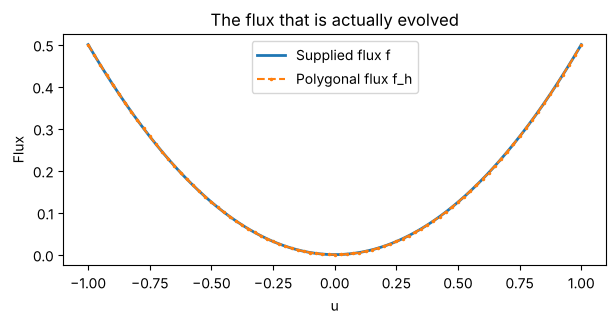

In [6]:
u = np.linspace(u_grid[0], u_grid[-1], 1001)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(u, np.broadcast_to(f(u), u.shape), label="Supplied flux f", linewidth=2)
ax.plot(flux.u_grid, flux.f_values, ".--", label="Polygonal flux f_h", markersize=3)
ax.set(xlabel="u", ylabel="Flux", title="The flux that is actually evolved")
ax.legend()
plt.show()


## 3. Space–time diagram and profile


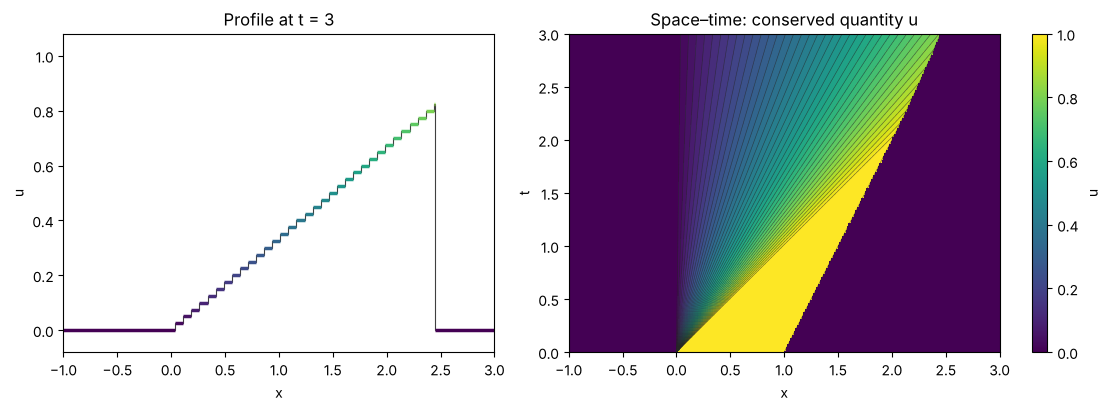

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
plot_profile(history, -1, ax=axes[0], cmap=cmap, norm=norm)
plot_spacetime(history, ax=axes[1], cmap=cmap, norm=norm)
plt.show()


## 4. Move through time
The slider selects a saved time. Play advances through the saved frames; all controls reuse the completed calculation.


In [8]:
viewer = dashboard(history, cmap=cmap)
display(viewer)


Interactive widget: run this notebook in Jupyter or Colab to use it. Viewers without a kernel (GitHub, VS Code preview) cannot display it.


## 5. Profile snapshots


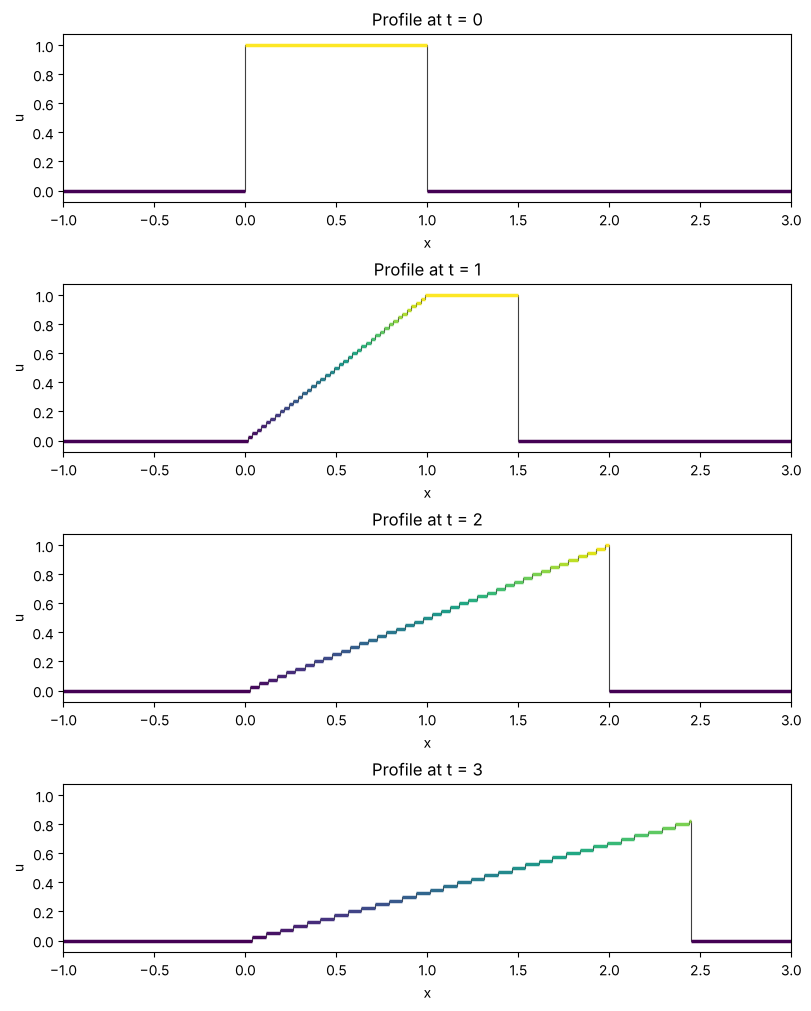

In [9]:
# Snapshots use the exact step boundaries, not the space-sampling grid.
fig, axes = plt.subplots(len(snapshot_times), 1, figsize=(8, 2.5*len(snapshot_times)),
                         constrained_layout=True, squeeze=False)
for ax, t in zip(axes[:, 0], snapshot_times):
    k = int(np.searchsorted(history.times, t))
    plot_profile(history, k, ax=ax, cmap=cmap, norm=norm)
plt.show()


### An additional time of your choice
This cell independently evolves a fresh tracker to the requested time, so it can go backwards or choose a time absent from the slider.


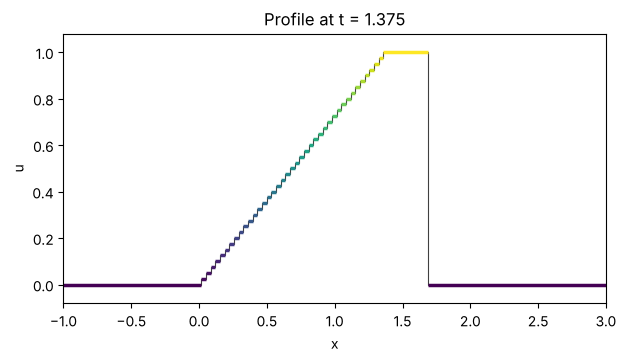

In [10]:
requested_time = 1.375  # EDIT; any finite nonnegative time
one = observe_tracker(make_tracker(), x, [requested_time])
plot_profile(one, cmap=cmap, norm=color_norm(np.r_[norm.vmin, norm.vmax, one.profiles[0][1]]))
plt.show()


## 6. Save figures and numerical samples
Files are written in the notebook’s working directory. In Colab use the Files panel to download them. Repeating this cell replaces these named export files.


In [11]:
output_dir = Path("front_tracking_exports")
output_dir.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
plot_spacetime(history, ax=ax, cmap=cmap, norm=norm)
fig.savefig(output_dir / "spacetime.png", dpi=180)
fig.savefig(output_dir / "spacetime.pdf")
plt.close(fig)
np.savez_compressed(output_dir / "solution.npz", x=history.x, times=history.times,
                    u=history.values, u_grid=flux.u_grid, f_values=flux.f_values,
                    segments=np.asarray(history.segments).reshape(-1, 4))
for k, t in enumerate(snapshot_times):
    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    plot_profile(history, int(np.searchsorted(history.times, t)), ax=ax, cmap=cmap, norm=norm)
    fig.savefig(output_dir / f"profile_{k:02d}.png", dpi=160)
    plt.close(fig)
print("Exports:", output_dir)


Exports: front_tracking_exports


## Experiments worth trying
- Set `f(u)=u` to see translation without deformation.
- Use Burgers data `[1, 0, -1]` at `[-0.5, 0.5]`: two shocks merge at $(x,t)=(0,1)$.
- Use `f(u)=u**3` with one jump from $-1$ to $1$: inspect the compound wave.
- Halve the state spacing while leaving display resolution fixed. Then increase only display resolution. These are different experiments.

The algorithm scans adjacent fronts at every interaction. Large state grids or many initial jumps can be expensive; begin with these modest settings.
